# 01 — Análisis Exploratorio de Datos (EDA)

| | |
|---|---|
| **Dataset** | `data/raw/bank-additional-full.csv` — Bank Marketing, UCI (DOI `10.24432/C5K306`) |
| **Ficha de variables** | `data/raw/bank-additional-names.txt` (Moro et al., 2014) |
| **Escenario de predicción** | **Antes de realizar la llamada** → `duration` se descarta (README §3) |
| **Objetivo** | Responder las preguntas del §4 y generar la evidencia para documentar el §5 del README |

**Reglas del proyecto (README):**

- Toda cifra de este notebook debe reproducirse ejecutando las celdas en orden con el entorno `.venv`.
- Cada decisión metodológica se documenta **donde se toma**, con su justificación.
- No se inventan resultados ni conclusiones sin evidencia.

## 1. Carga de datos

El archivo usa **punto y coma (`;`)** como separador y campos entrecomillados (formato de exportación de R, `read.table`).

- Sin indicar `sep=';'`, pandas interpretaría toda la fila como **una sola columna** → error clásico de lectura.
- Una vez cargado, los modelos **nunca ven el CSV**: solo trabajan con el DataFrame en memoria, por lo que el separador no afecta al modelado.
- El CSV original se conserva sin modificaciones en `data/raw/` (README §15).

In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/raw/bank-additional-full.csv', sep=';')

print(f'Registros: {df.shape[0]} | Columnas: {df.shape[1]}')
df.head()

Registros: 41188 | Columnas: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Dimensiones y tipos de variables (§4.3)

Clasificación según la ficha `bank-additional-names.txt` y según su momento de disponibilidad (escenario *antes de llamar*):

| Bloque | Variables | Disponibles antes de llamar |
|---|---|---|
| **A. Perfil del cliente** | `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` | Sí |
| **B. Último contacto de la campaña actual** | `contact`, `month`, `day_of_week`, `duration` | No (se ejecuta durante la campaña) |
| **C. Histórico de campañas** | `campaign`, `pdays`, `previous`, `poutcome` | `campaign` pertenece a la ejecución; el resto, sí |
| **D. Contexto socioeconómico** | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Sí (indicadores públicos) |
| **Salida** | `y` | — |

En esta sección solo **describimos**; la decisión de qué entra al modelo queda registrada en la sección 10.

In [2]:
df.info()

num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]

resumen = pd.DataFrame({
    'tipo': [str(t) for t in df.dtypes],
    'no_nulos': df.notnull().sum(),
    'n_unicos': df.nunique(),
    'ejemplo': [str(df[c].unique()[:3].tolist()) for c in df.columns],
})
print(f'Numéricas ({len(num_cols)}):', num_cols)
print(f'Categóricas ({len(cat_cols)}):', cat_cols)
resumen

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

,tipo,no_nulos,n_unicos,ejemplo
age,int64,41188,78,"[56, 57, 37]"
job,str,41188,12,"['housemaid', 'services', 'admin.']"
marital,str,41188,4,"['married', 'single', 'divorced']"
education,str,41188,8,"['basic.4y', 'high.school', 'basic.6y']"
default,str,41188,3,"['no', 'unknown', 'yes']"
housing,str,41188,3,"['no', 'yes', 'unknown']"
loan,str,41188,3,"['no', 'yes', 'unknown']"
contact,str,41188,2,"['telephone', 'cellular']"
month,str,41188,10,"['may', 'jun', 'jul']"
day_of_week,str,41188,5,"['mon', 'tue', 'wed']"


## 3. Distribución de la variable objetivo (§4.1 y §4.2)

Por qué importa:

- Define la **métrica** (§4.9): con clases desbalanceadas, el *accuracy* engaña (predecir siempre `no` daría ~89% de acierto sin aprender nada).
- Define la **estratificación** del split (§6): la proporción de `yes` debe mantenerse en train/test.
- Define si hace falta **tratamiento del desbalance** (§6): `class_weight`, remuestreo, etc.

         n     %
y               
no   36548  88.7
yes   4640  11.3

Relación no:yes = 7.9 : 1


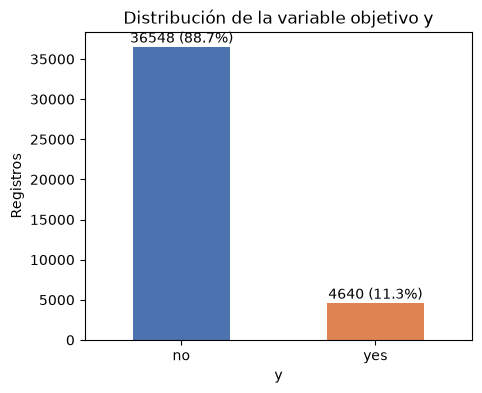

In [3]:
vc = df['y'].value_counts()
tabla_y = pd.DataFrame({'n': vc, '%': (vc / len(df) * 100).round(1)})
print(tabla_y)
print(f'\nRelación no:yes = {vc["no"] / vc["yes"]:.1f} : 1')

ax = vc.plot(kind='bar', color=['#4C72B0', '#DD8452'], rot=0, figsize=(5, 4),
             title='Distribución de la variable objetivo y')
ax.set_ylabel('Registros')
for i, v in enumerate(vc):
    ax.text(i, v + 500, f'{v} ({v / len(df) * 100:.1f}%)', ha='center')
plt.show()

## 4. Categorías y valores únicos (§4.4)

Listamos los valores reales de cada columna categórica para:

- Confirmar que coinciden con la ficha del dataset.
- Detectar la categoría `unknown` (missing disfrazado, ficha línea 72) y categorías estructurales como `nonexistent`.
- Observar rarezas (por ejemplo, categorías con muy pocos registros).

In [4]:
for c in cat_cols:
    vc = df[c].value_counts()
    print(f'\n--- {c} ({len(vc)} valores) ---')
    print(vc.to_string())


--- job (12 valores) ---
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330

--- marital (4 valores) ---
marital
married     24928
single      11568
divorced     4612
unknown        80

--- education (8 valores) ---
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18

--- default (3 valores) ---
default
no         32588
unknown     8597
yes            3

--- housing (3 valores) ---
housing
yes        21576
no         18622
unknown      990

--- loan (3 valores) ---
loan
no         33950
yes         6248
unknown      990

--- contact (2 valores) ---
contact
cellular     2614

## 5. Tratamiento conceptual de `unknown` (§4.4 y §5)

La ficha del dataset (línea 72) es explícita: **los missing de los atributos categóricos están codificados con la etiqueta `unknown`**. No son celdas vacías (verificamos: 0 celdas vacías), pero **sí son ausencia de información**.

**Opciones teóricas:**

| Opción | Contras |
|---|---|
| Eliminar las filas con `unknown` | Pierde registros (hasta 20,9% en `default`); sesga la muestra |
| Imputar (moda, etc.) | *Inventa* datos que nunca se registraron; puede crear patrones falsos |
| **Mantener `unknown` como categoría** ✅ | No inventa nada; el propio `unknown` puede ser informativo (ej.: clientes cuyos datos nunca se completaron) |

**Decisión documentada:** mantener `unknown` como categoría más en el preprocesamiento (§6), aplicando codificación que le dé su propio peso (One-Hot). No se imputa.

**Caso particular — `default`:** ~21% `unknown` y **solo 3 registros `yes`** de 41.188 → casi constante. Se marca como **candidata a descartarse** en el preprocesamiento; aquí se conserva para no decidir sin antes comparar su efecto.

## 6. Centinelas y consistencia (§4.5)

Hay valores que **no son datos reales sino códigos de «no corresponde»**:

- `pdays = 999` → el cliente **nunca** fue contactado en campañas anteriores (ficha, línea 59). No es un número: saca la media del 960+ si no se trata.
- `poutcome = nonexistent` → sin campaña previa (no es *missing*, es historia).
- `previous = 0` → sin contactos previos.
- `month` solo tiene 10 valores → la campaña **no corría en enero/febrero** (dato real, no fallo).

**Verificación de consistencia:** si los datos son internamente coherentes, `pdays=999`, `previous=0` y `poutcome=nonexistent` deberían coincidir en las mismas filas. Lo comprobamos con cruces de tablas.

In [5]:
es_999 = df['pdays'] == 999
es_prev0 = df['previous'] == 0
es_nonexist = df['poutcome'] == 'nonexistent'

print(f'pdays == 999          : {es_999.sum()}')
print(f'previous == 0         : {es_prev0.sum()}')
print(f'poutcome == nonexistent: {es_nonexist.sum()}')

print('\nCruce  pdays==999  vs  poutcome==nonexistent:')
print(pd.crosstab(es_999, es_nonexist))

print('\nCruce  previous==0  vs  poutcome==nonexistent:')
print(pd.crosstab(es_prev0, es_nonexist))

print('\nMeses presentes:', sorted(df['month'].unique()))
print('Meses ausentes :', sorted(set(['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']) - set(df['month'])))

pdays == 999          : 39673
previous == 0         : 35563
poutcome == nonexistent: 35563

Cruce  pdays==999  vs  poutcome==nonexistent:
poutcome  False  True 
pdays                 
False      1515      0
True       4110  35563

Cruce  previous==0  vs  poutcome==nonexistent:
poutcome  False  True 
previous              
False      5625      0
True          0  35563

Meses presentes: ['apr', 'aug', 'dec', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
Meses ausentes : ['feb', 'jan']


### Resultado de la verificación de consistencia

- `previous == 0` ↔ `poutcome = nonexistent`: **coinciden al 100%** (35.563 filas) ✓
- `pdays = 999`: aparece en **39.673** filas, pero **4.110 de ellas tienen `previous > 0` y `poutcome` conocido** → contradicen la ficha («999 = nunca contactado»). De los 5.625 registros con historia previa, solo 1.515 traen un `pdays` real.
- **Conclusión**: `999` **no es fiable** como marcador de «sin campaña previa». Lo fiable es `previous`/`poutcome`.
- **Decisión documentada para §6**: usar `previous`/`poutcome` como fuente de verdad histórica; tratar `pdays` de forma explícita (por ejemplo, derivar un indicador `contactado_antes = previous > 0` y/o codificar el 999 como centinela), nunca dejarlo como número crudo sin señalizar.
- `month` sin `jan`/`feb`: ventana de la campaña, **dato real, no error**.

## 7. Registros duplicados (§4.5)

**Por qué importa:**

- Una fila idéntica cuenta doble y **distorsiona entrenamiento y métricas**.
- Si un duplicado cae en train y otro en test, el modelo «ve» la respuesta antes → **fuga de información artificial**.

**Decisión documentada:** eliminar las filas duplicadas exactas (solo copias redundantes, no clientes distintos reales — al ser idénticas en las 21 columnas no aportan información nueva) **en el preprocesamiento (§6)**, dejando constancia del número aquí.

In [6]:
n_redundantes = int(df.duplicated().sum())
dups = df[df.duplicated(keep=False)]

print(f'Copias redundantes (duplicated): {n_redundantes}')
print(f'Filas implicadas en grupos duplicados: {len(dups)}')
print(f'Porcentaje sobre el total: {n_redundantes / len(df) * 100:.3f}%')

dups.sort_values(df.columns.tolist()).head(10)

Copias redundantes (duplicated): 12
Filas implicadas en grupos duplicados: 24
Porcentaje sobre el total: 0.029%


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


## 8. Distribuciones numéricas y valores atípicos (§5)

- `describe()` da el panorama central y de dispersión.
- Los histogramas permiten ver sesgos y colas largas (`campaign`, `previous` están muy concentradas a la izquierda).
- **Atípicos por IQR** (rango intercuartílico): se cuentan valores fuera de `[Q1 − 1,5·IQR , Q3 + 1,5·IQR]`. Un atípico **no es un error**: `campaign = 56` (56 llamadas a un cliente) es posible; se señala para decidir su tratamiento en §6.
- `pdays` se histograma con su centinela 999 incluido a propósito: se **ve** el problema (pico artificial en 999).

In [7]:
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


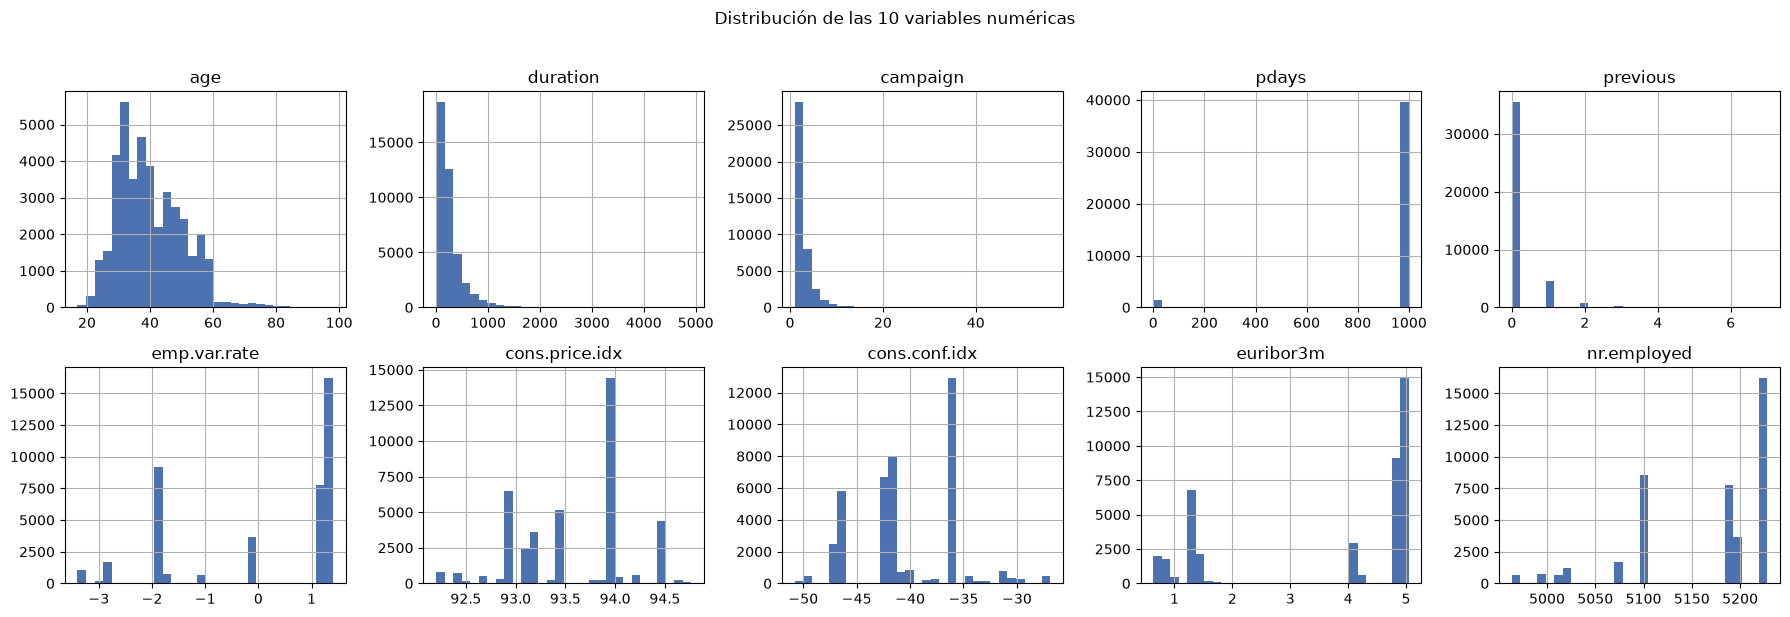

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, c in zip(axes.flat, num_cols):
    df[c].hist(bins=30, ax=ax, color='#4C72B0')
    ax.set_title(c)
fig.suptitle('Distribución de las 10 variables numéricas', y=1.02)
plt.tight_layout()
plt.show()

In [9]:
def contar_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.DataFrame(
    {c: [contar_outliers(df[c])] for c in ['age', 'campaign', 'previous', 'duration']},
    index=['n_valores_fuera_de_IQR']
)

,age,campaign,previous,duration
n_valores_fuera_de_IQR,469,2406,5625,2963


## 9. Relaciones entre características y con el objetivo (§4.6)

1. **Tasa de suscripción por categoría**: para cada valor de una categórica, ¿qué % terminó en `yes`? Si una categoría se desvía del promedio (11,3%), aporta señal.
2. **Comparación numéricas vs `y`** con boxplots.
3. **Correlaciones** entre numéricas y con el objetivo (`y_bin` es una columna auxiliar creada solo para poder correlacionar; se descarta después).

Nota: se muestra `duration` vs `y` **como evidencia de por qué se excluye** (la ficha advierte que domina la salida) — no entrará al modelo.


--- % de suscripción según job ---
job
blue-collar       6.9
services          8.1
entrepreneur      8.5
housemaid        10.0
self-employed    10.5
technician       10.8
unknown          11.2
management       11.2
admin.           13.0
unemployed       14.2
retired          25.2
student          31.4

--- % de suscripción según marital ---
marital
married     10.2
divorced    10.3
single      14.0
unknown     15.0

--- % de suscripción según education ---
education
basic.9y                7.8
basic.6y                8.2
basic.4y               10.2
high.school            10.8
professional.course    11.3
university.degree      13.7
unknown                14.5
illiterate             22.2

--- % de suscripción según default ---
default
yes         0.0
unknown     5.2
no         12.9

--- % de suscripción según housing ---
housing
unknown    10.8
no         10.9
yes        11.6

--- % de suscripción según loan ---
loan
unknown    10.8
yes        10.9
no         11.3



--- % de suscripción según poutcome ---
poutcome
nonexistent     8.8
failure        14.2
success        65.1

--- % de suscripción según contact ---
contact
telephone     5.2
cellular     14.7


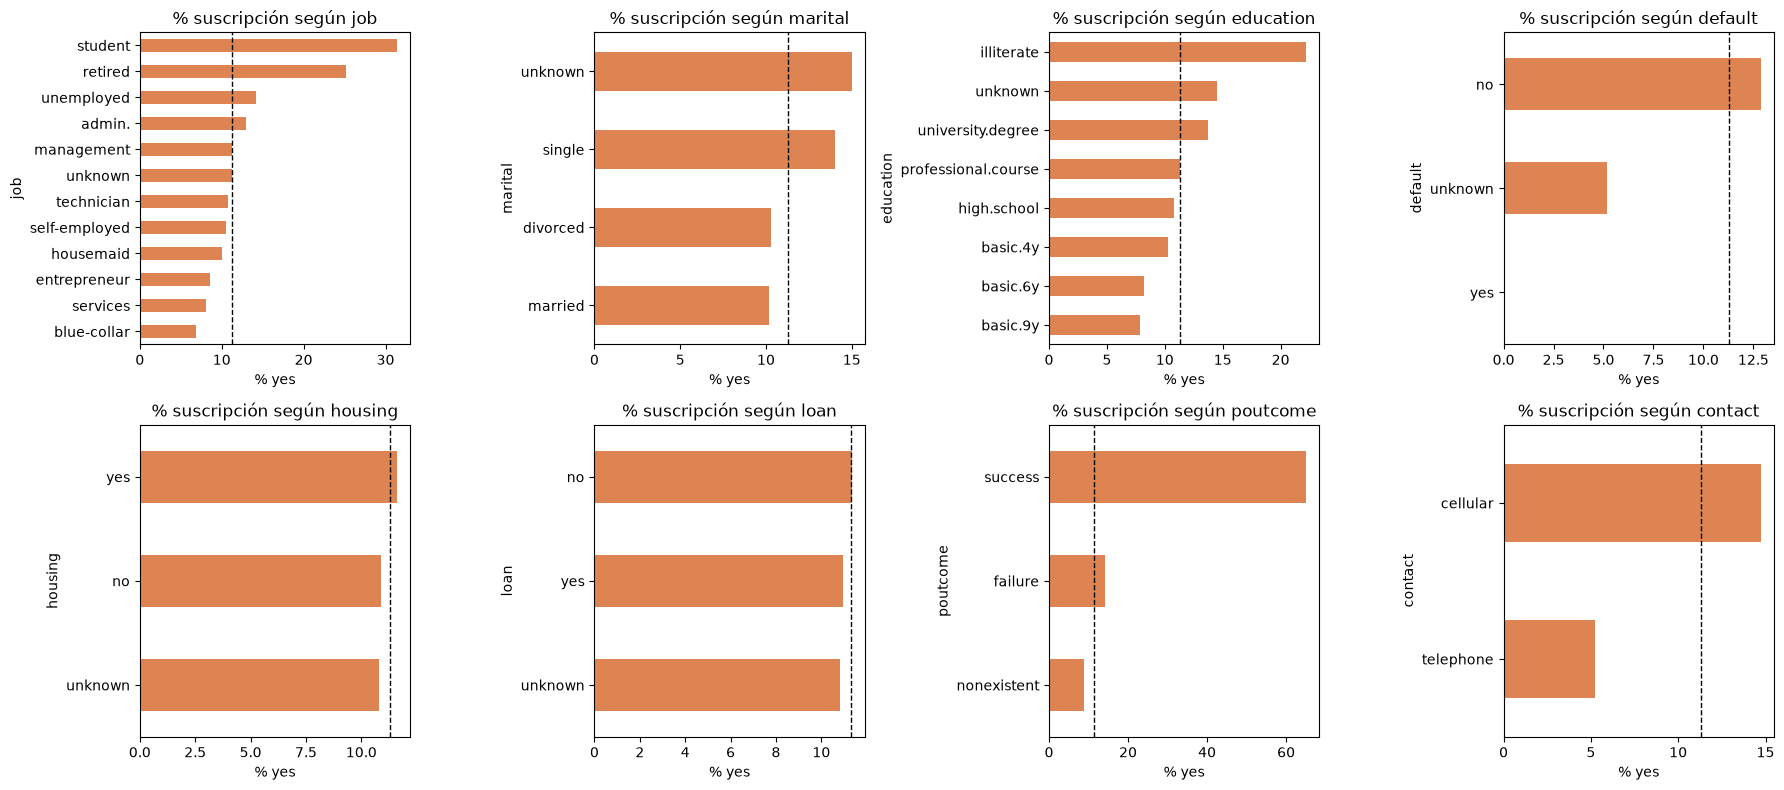

Tasa de éxito global: 11.3% — la línea punteada marca ese promedio.


In [10]:
cats_plot = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome', 'contact']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flat, cats_plot):
    tasas = df.groupby(c)['y'].apply(lambda s: (s == 'yes').mean() * 100).sort_values()
    print(f'\n--- % de suscripción según {c} ---')
    print(tasas.round(1).to_string())
    tasas.plot(kind='barh', ax=ax, color='#DD8452')
    ax.axvline(11.3, color='black', ls='--', lw=1)
    ax.set_title(f'% suscripción según {c}')
    ax.set_xlabel('% yes')
plt.tight_layout()
plt.show()

print('Tasa de éxito global: 11.3% — la línea punteada marca ese promedio.')

Duración media de la llamada (seg), según y:
y
no     220.8
yes    553.2
Name: duration, dtype: float64

→ Diferencia enorme: duration predeciría y casi por sí sola. Por eso la excluimos
  (ficha línea 56): el escenario es ANTES de llamar. Es fuga de información.



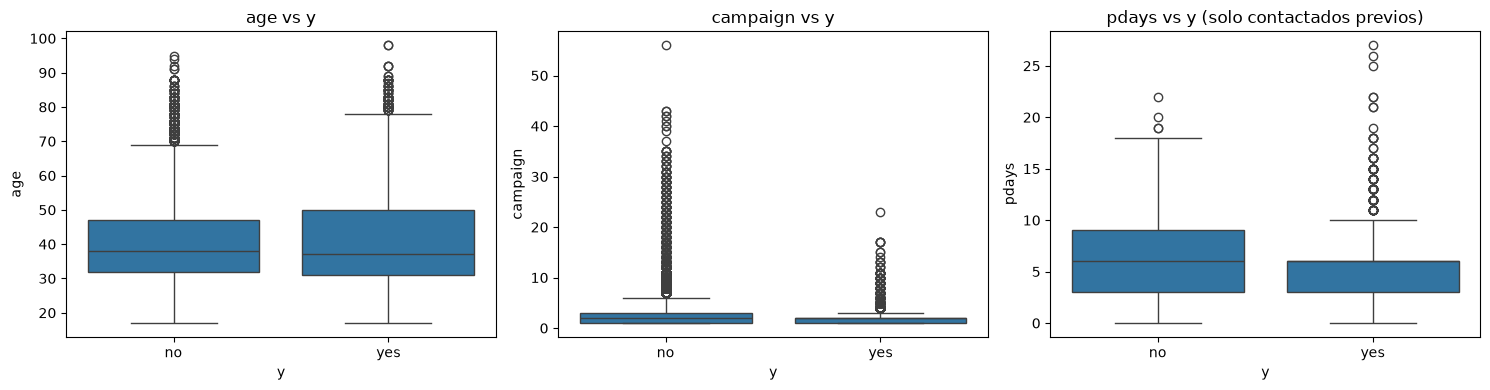

In [11]:
print('Duración media de la llamada (seg), según y:')
print(df.groupby('y')['duration'].mean().round(1))
print('\n→ Diferencia enorme: duration predeciría y casi por sí sola. Por eso la excluimos')
print('  (ficha línea 56): el escenario es ANTES de llamar. Es fuga de información.\n')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x='y', y='age', ax=axes[0])
axes[0].set_title('age vs y')
sns.boxplot(data=df, x='y', y='campaign', ax=axes[1])
axes[1].set_title('campaign vs y')
sns.boxplot(data=df[df['pdays'] != 999], x='y', y='pdays', ax=axes[2])
axes[2].set_title('pdays vs y (solo contactados previos)')
plt.tight_layout()
plt.show()

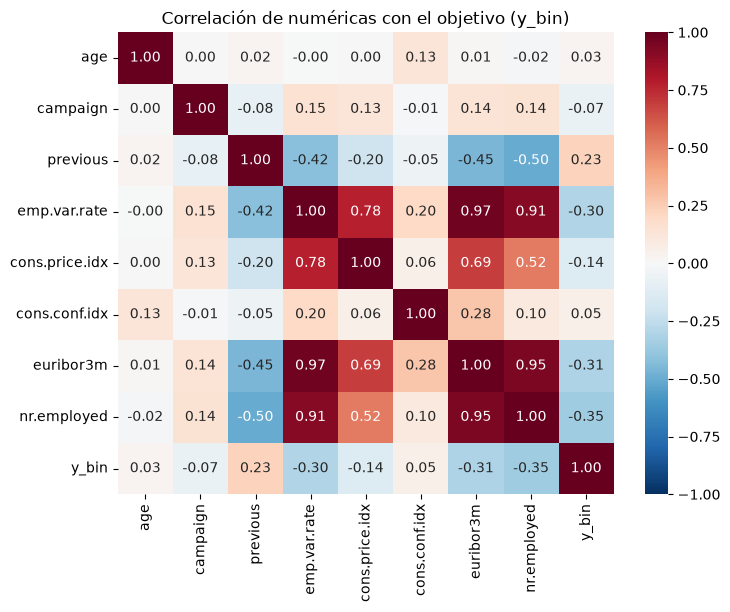

Correlación con y_bin (de mayor a menor en valor absoluto):
nr.employed      -0.355
euribor3m        -0.308
emp.var.rate     -0.298
previous          0.230
cons.price.idx   -0.136
campaign         -0.066
cons.conf.idx     0.055
age               0.030
Name: y_bin, dtype: float64


In [12]:
df['y_bin'] = (df['y'] == 'yes').astype(int)

corr_cols = ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx',
             'cons.conf.idx', 'euribor3m', 'nr.employed', 'y_bin']
corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlación de numéricas con el objetivo (y_bin)')
plt.show()

print('Correlación con y_bin (de mayor a menor en valor absoluto):')
print(corr['y_bin'].drop('y_bin').reindex(corr['y_bin'].drop('y_bin').abs().sort_values(ascending=False).index).round(3))

## 10. Disponibilidad antes de llamar y fuga de información (§4.7, §4.8, promesa del §3)

El README §3 comprometió a evaluar cada variable del bloque *«last contact of the current campaign»* con el criterio de disponibilidad. Resultado:

| Variable | Bloque | ¿Disponible antes de llamar? | **Decisión** | Justificación |
|---|---|---|---|---|
| `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` | Perfil | ✅ Sí | **ENTRA** | Datos del CRM |
| `pdays`, `previous`, `poutcome` | Histórico | ✅ Sí | **ENTRA** | Campañas anteriores, ya ocurridas |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Macro | ✅ Sí | **ENTRA** | Indicadores públicos conocidos |
| `duration` | Último contacto | ❌ No | **FUERA** | Ficha l.56: no se conoce antes de la llamada; después, `y` ya es obvio |
| `campaign` | Ejecución | ❌ No | **FUERA** | Acumula los contactos de la campaña actual: antes de llamar aún no existe |
| `month` | Último contacto | ❌ No | **FUERA** | Es el mes en que ocurrió el último contacto, no el planeado |
| `day_of_week` | Último contacto | ❌ No | **FUERA** | Ídem |
| `contact` | Último contacto | ❌ No | **FUERA** | La ficha lo agrupa con el último contacto; se descarta por criterio estricto (decisión revisable) |

**Set final de modelado: 15 features** (7 perfil + 3 histórico + 5 macro).

`duration` podría usarse aparte **solo como benchmark** (README §3), nunca en el modelo principal.

## 11. Métrica candidata (§4.9)

Contexto: desbalance ≈ 1:8 y **los dos errores cuestan distinto**:

- **Falso positivo** → llamamos a alguien que no contrata → llamada desperdiciada (costo pequeño).
- **Falso negativo** → no llamamos a alguien que sí contrataría → oportunidad perdida (costo alto).

| Métrica | Para qué sirve aquí |
|---|---|
| **ROC-AUC** | Comparar modelos sin depender del umbral (candidata a métrica principal) |
| **F1 / Precision / Recall** | Traducir al punto de operación (cuántas llamadas hacen falta) |
| **PR-AUC** | Más informativa que ROC-AUC con clases desbalanceadas |
| Accuracy | **No usar como principal**: engaña con desbalance |

**Decisión formal de la métrica principal: pendiente en §9 del README**, después del baseline (§7) y con la evidencia de los modelos comparados — no se decide aquí para no anticipar resultados.

## 12. Principales hallazgos (§5)

1. **Dimensiones**: 41.188 registros × 21 columnas; **0 celdas vacías**; **0 NaN**.
2. **Objetivo desbalanceado**: 88,7% `no` / 11,3% `yes` (≈ 1:8) → obliga a métricas más allá del accuracy y a estratificar el split.
3. **Missing disfrazado**: `unknown` en categóricas (máximo: `default` ~21%, `education` 4,2%); decisión: **no imputar, mantener como categoría**.
4. **`default` casi constante**: solo 3 `yes` → candidata a descartarse en preprocesamiento.
5. **Consistencia de centinelas parcial**: `previous=0` ↔ `poutcome=nonexistent` coinciden al 100% (35.563), pero **4.110 filas tienen `pdays=999` con historia previa** (`previous>0`) → contradicción con la ficha; `pdays` no usarse crudo sin tratamiento. `month` no incluye ene/feb por la ventana de la campaña.
6. **12 filas duplicadas exactas** (0,03%) → se eliminan en preprocesamiento con registro de la cifra.
7. **Atípicos**: `campaign` llega a 56 (promedio 2,6) y `previous` a 7 → señalar, no eliminar automáticamente; tratamiento a definir en §6.
8. **Señal fuerte en variables históricas**: `poutcome=success` claramente por encima del promedio de suscripción (ver celda 9).
9. **Multicolinealidad en el bloque macro**: `euribor3m`, `nr.employed` y `emp.var.rate` se mueven juntos (ver mapa de calor) → a tener en cuenta en modelos lineales (regularización) y al interpretar importancias.
10. **Set de modelado**: **15 features IN / 5 FUERA** (`duration`, `campaign`, `month`, `day_of_week`, `contact`) — sección 10.

## 13. Próximos pasos → Preprocesamiento (§6 del README)

- Eliminar las **12 filas duplicadas**.
- Tratar **`pdays`**: 4.110 filas contradicen el centinela 999 → derivar indicador histórico desde `previous`/`poutcome` y/o codificar 999 explícitamente (ver sección 6).
- Eliminar las **5 columnas fuera del escenario** (`duration`, `campaign`, `month`, `day_of_week`, `contact`).
- Separar features (`X`, 15 columnas) de objetivo (`y`).
- Split train/test **estratificado** por `y`.
- Codificación: One-Hot para categóricas (incluye `unknown` como categoría propia); escala para numéricas si el modelo lo requiere.
- Decidir tratamiento de `default` (candidata a descarte) y de atípicos de `campaign`.
- Evaluar si hace falta contrarrestar el desbalance (`class_weight='balanced'` o remuestreo) — probado por modelo, no asumido.
- Construir todo con `Pipeline` + `ColumnTransformer` para evitar fuga (fit solo en train).